# 02 · Does funding predict the price?

**The idea:** when funding is very high, a lot of people are betting on a rise and paying a lot to hold that bet. If the price doesn't follow, many close or get liquidated, and that pushes the price **down**. If true, very high funding would announce drops.

**The question:** does this hour's extreme funding predict how far the price moves over the **next 8 hours**?

Steps:
1. For each hour, compute how much the price moved over the **next** 8 hours.
2. Measure how **extreme** each hour's funding is compared with that week's normal.
3. Sort all hours from lowest to highest funding, split them into **5 equal groups** and look at the average price move in each group.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

COINS = ["HYPE", "BTC", "ETH", "SOL"]
COIN = "HYPE"   # Hyperliquid's own token; change to "BTC", "ETH" or "SOL" to look at another coin
df = pd.read_csv(f"../data/{COIN}.csv", parse_dates=["time"])

## Step 1: the future return

`shift(-8)` takes the price 8 rows ahead (8 hours later). The future return is the % change from now until then.

**This is what we want to predict.** It is only used to measure; it can never be part of the rule, because in real life the future is unknown.

In [2]:
H = 8  # horizon in hours: try 4 and 24 too
df["fut_ret"] = df["close"].shift(-H) / df["close"] - 1
df[["time", "close", "fut_ret"]].head(10)

,time,close,fut_ret
0,2026-04-07 02:00:00,36.372,0.000605
1,2026-04-07 03:00:00,36.400,-0.000467
2,2026-04-07 04:00:00,36.469,-0.009954
3,2026-04-07 05:00:00,36.185,-0.007075
4,2026-04-07 06:00:00,36.221,-0.009470
5,2026-04-07 07:00:00,36.195,-0.004448
6,2026-04-07 08:00:00,36.420,-0.005601
7,2026-04-07 09:00:00,36.925,-0.012864
8,2026-04-07 10:00:00,36.394,-0.000659
9,2026-04-07 11:00:00,36.383,0.021466


## Step 2: how extreme is funding? (the *z-score*)

A funding of 0.001% can be high in a quiet week and normal in a wild one. So we compare it with **its own previous week** (168 hours):

`z = (funding now − last week's mean) / last week's standard deviation`

- `z = 0`: normal funding.
- `z = +2`: much higher than usual.
- `z = −2`: much lower than usual.

`rolling(168)` computes the mean and deviation using only the **previous** 168 hours, so no future information leaks in.

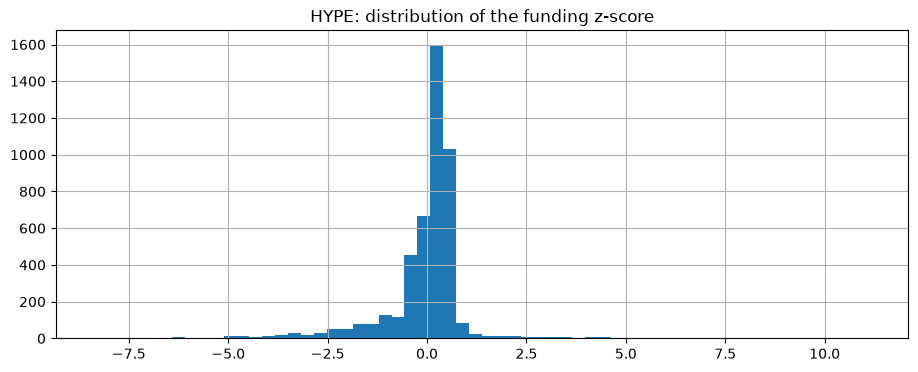

In [3]:
W = 168
mean = df["fundingRate"].rolling(W).mean()
std = df["fundingRate"].rolling(W).std()
df["z"] = (df["fundingRate"] - mean) / std

df = df.dropna(subset=["z", "fut_ret"])  # the first hours have no previous week
df["z"].hist(bins=60); plt.title(f"{COIN}: distribution of the funding z-score"); plt.show()

## Step 3: the 5 groups

`pd.qcut(..., 5)` sorts the hours by z and splits them into 5 groups of equal size:
- Group 1: the 20% of hours with the **lowest** funding.
- Group 5: the 20% with the **highest** funding.

Then we compute the average future return of each group.

         mean %  count
group                 
1      0.019503    925
2      0.023672    927
3      0.142990    926
4      0.397230    923
5      0.030816    924


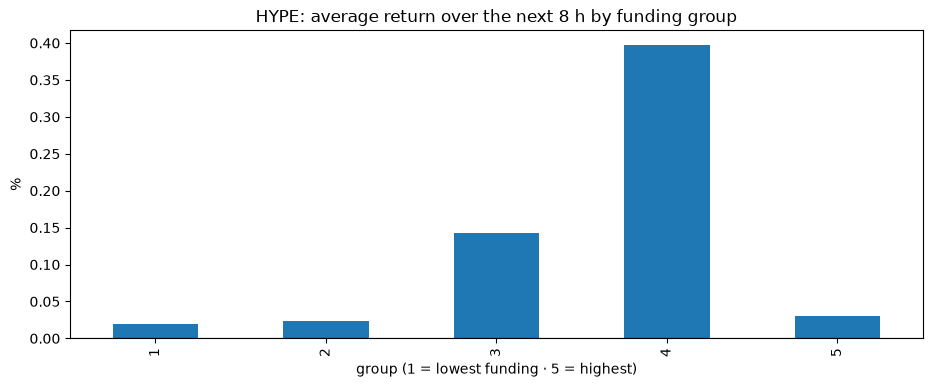

In [4]:
df["group"] = pd.qcut(df["z"], 5, labels=[1, 2, 3, 4, 5])
table = df.groupby("group", observed=True)["fut_ret"].agg(["mean", "count"])
table["mean %"] = table["mean"] * 100
print(table[["mean %", "count"]])

table["mean %"].plot.bar(title=f"{COIN}: average return over the next {H} h by funding group")
plt.xlabel("group (1 = lowest funding · 5 = highest)"); plt.ylabel("%"); plt.axhline(0, color="black", lw=0.8); plt.show()

## How to read the chart

- **If the bars fall (or rise) in order from 1 to 5**, there is a **possible signal**: funding says something about the future price.
- **If the bars are jumbled or all similar**, there is **no signal**. That is a valid result and it gets published too.

**Careful:** with a few months of data, a small difference can be pure chance. That is what notebook 03 is for.

## Extra: does it repeat in other coins?
If the pattern is real, it should show up in other coins too. If it appears in only one, suspect chance.

In [5]:
for coin in COINS:
    d = pd.read_csv(f"../data/{coin}.csv", parse_dates=["time"])
    d["fut_ret"] = d["close"].shift(-H) / d["close"] - 1
    d["z"] = (d["fundingRate"] - d["fundingRate"].rolling(W).mean()) / d["fundingRate"].rolling(W).std()
    d = d.dropna(subset=["z", "fut_ret"])
    g = d.groupby(pd.qcut(d["z"], 5, labels=[1, 2, 3, 4, 5]), observed=True)["fut_ret"].mean() * 100
    print(coin.ljust(4), " · ".join(f"G{k}: {v:+.3f}%" for k, v in g.items()))

HYPE G1: +0.020% · G2: +0.024% · G3: +0.143% · G4: +0.397% · G5: +0.031%
BTC  G1: +0.007% · G2: +0.078% · G3: +0.051% · G4: +0.046% · G5: -0.082%
ETH  G1: +0.059% · G2: -0.050% · G3: +0.027% · G4: -0.233% · G5: +0.179%
SOL  G1: -0.047% · G2: +0.204% · G3: -0.083% · G4: -0.008% · G5: +0.154%
